In [1]:
#--------PLAN-------
plan = {
    'notes' : [
        'log_price is right skewed', 
        'datasets for each model family (one for trees one for linear)'
               ],
    'plan' : [
        'adding a quick flag to enable smoke testing of the notebook as full dataset will take an hour',
        'CV is made on the train dataset only and the test is called once in the testing phase',
        {'models_linear' : {
            'ridge regression' : 'used because the data has multicollinearity to prevent overfitting',
            'lassso' : 'L1 regularization to create a more sparse model'
        },
        'models_trees' : {
            'decison trees' : 'the most simple method of tree models used as a control',
            'random forest' : 'robust to ooutliers, performs well with high dimesionality',
            'XGBoost' : 'enhances RF by learning from past mistakes'
        }},
        'used the Random seed to ensure same run everytime', 
    ],
    'structure' : [
        'each model is tuned on 3 fold CV from a 60k subsample of the train',
        'this is to keep tuning cheap',
        'final 5 fold CV on all the train data',
        '5-fold CV gives a more reliable score than the 60k subsample, and the models are ranked by it, never by test',
        'then each model is refit on all of train and predicted on the test set once, only to confirm the CV score'
    ] 
}

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV, GridSearchCV,
                                     validation_curve, learning_curve, train_test_split)
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 40)

RANDOM_seed = 202301274
SEED = RANDOM_seed % (2**32) 
#quick flag to smoke test
#if false, will run on the full dataset   
QUICK = False                         

if QUICK:
    TRAIN_N, TEST_N, SUB_N = 6_000, 3_000, 3_000
    N_ITER = dict(ridge=3, lasso=3, rf=2, xgb=2)
    RF_SEARCH_TREES, RF_FINAL_TREES = 10, 20
    XGB_SEARCH_TREES, XGB_MAX_TREES = 30, 300
else:
    TRAIN_N, TEST_N, SUB_N = None, None, 60_000
    N_ITER = dict(ridge=25, lasso=20, rf=20, xgb=40)
    RF_SEARCH_TREES, RF_FINAL_TREES = 150, 300
    XGB_SEARCH_TREES, XGB_MAX_TREES = 600, 4000

TARGET, PRICE = "log_price", "price"
os.makedirs("models", exist_ok=True)

train_trees = pd.read_parquet("prepared/trees_train.parquet")
train_lin = pd.read_parquet("prepared/linear_train.parquet")
if QUICK:
    keep = train_trees.sample(TRAIN_N, random_state=SEED).index
    train_trees, train_lin = train_trees.loc[keep], train_lin.loc[keep]

def split_xy(frame):
    return frame.drop(columns=[PRICE, TARGET]), frame[TARGET], frame[PRICE]

Xt_tr, y_tr, p_tr = split_xy(train_trees)     # trees copy
Xl_tr, y_l, p_l = split_xy(train_lin)         # linear copy
#sainty check
assert Xt_tr.index.equals(Xl_tr.index) and np.allclose(y_tr, y_l), "the two copies must hold the same rows in the same order"
print(f"train rows: {len(Xt_tr):,} | trees copy: {Xt_tr.shape[1]} features | linear copy: {Xl_tr.shape[1]} features | QUICK={QUICK}")

train rows: 184,008 | trees copy: 18 features | linear copy: 361 features | QUICK=False


In [3]:
assert Xt_tr.isna().sum().sum() == 0 and Xl_tr.isna().sum().sum() == 0, "prepared data should have no missing values"
assert y_tr.between(np.log(500), np.log(200_000)).all(), "log_price outside the cleaned range"
assert (Xl_tr.dtypes != "object").all() and (Xt_tr.dtypes != "object").all(), "all features must be numeric"

CAT_COLS = ["manufacturer", "model_full", "condition", "fuel", "title_status", "transmission",
            "drive", "size", "type", "paint_color", "state"]
NUM_COLS = ["age_from_year", "odometer", "cylinders_num"]
FLAG_COLS = ["is_carvana", "has_vin", "damaged_title", "cylinders_missing"]
assert list(Xt_tr.columns) == CAT_COLS + NUM_COLS + FLAG_COLS, "unexpected tree-copy columns"

print("trees copy  :", Xt_tr.shape, "| linear copy:", Xl_tr.shape)
print(f"log_price   : min {y_tr.min():.2f}, median {y_tr.median():.2f}, max {y_tr.max():.2f}  "
      f"(= ${np.exp(y_tr.min()):,.0f} / ${np.exp(y_tr.median()):,.0f} / ${np.exp(y_tr.max()):,.0f})")
print("levels per categorical column (trees copy):", {c: int(Xt_tr[c].nunique()) for c in CAT_COLS})

trees copy  : (184008, 18) | linear copy: (184008, 361)
log_price   : min 6.21, median 9.38, max 11.74  (= $500 / $11,900 / $124,900)
levels per categorical column (trees copy): {'manufacturer': 43, 'model_full': 4278, 'condition': 7, 'fuel': 6, 'title_status': 7, 'transmission': 4, 'drive': 4, 'size': 5, 'type': 13, 'paint_color': 13, 'state': 51}


In [4]:
def evaluate(y_true_log, y_pred_log, price_true=None):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    usd_true = np.exp(y_true_log) if price_true is None else np.asarray(price_true)
    usd_pred = np.exp(y_pred_log)
    return {
        "rmse_log": root_mean_squared_error(y_true_log, y_pred_log),
        "r2_log": r2_score(y_true_log, y_pred_log),
        #mean absolute error
        "mae_usd": np.mean(np.abs(usd_true - usd_pred)),
        "rmse_usd": root_mean_squared_error(usd_true, usd_pred),
        #median absolute percentage error
        "mdape_pct": 100 * np.median(np.abs(usd_true - usd_pred) / usd_true),
    }
#used dollar values to show how the model fails in understandable figures

# quick self-test: a perfect prediction must give zero error
print(evaluate([9.0, 10.0], [9.0, 10.0]))

{'rmse_log': 0.0, 'r2_log': 1.0, 'mae_usd': np.float64(0.0), 'rmse_usd': 0.0, 'mdape_pct': np.float64(0.0)}


In [5]:
#CV and tuning the subsamples
#creating 5 groups with all the price ranges 
bins = pd.qcut(y_tr, 10, labels=False, duplicates="drop").values

def make_folds(n_splits, X, strat):
    #using stratificaton to keep the data stable with its skewed nature
    return list(StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(X, strat))

cv5 = make_folds(5, Xt_tr, bins)

#drawing the subsample
rng = np.random.default_rng(SEED)
#sorting the folds                    #to not ask for more rows than present   replace = false to not pick the same row twice 
sub_pos = np.sort(rng.choice(len(Xt_tr), size=min(SUB_N, len(Xt_tr)), replace=False)) #stores positons only
#subsample by taking the rows at the positions in the sub_pos for each the tree, linear, and the price
Xt_sub, Xl_sub, y_sub = Xt_tr.iloc[sub_pos], Xl_tr.iloc[sub_pos], y_tr.iloc[sub_pos]
#choosign 3 folds only to keep the tuning affordable 
cv3 = make_folds(3, Xt_sub, bins[sub_pos])

# proof that stratification works: every fold has nearly the same target distribution
fold_check = pd.DataFrame([{"fold": i, "n_val": len(va), "mean_log_price": y_tr.iloc[va].mean(),
                            "std_log_price": y_tr.iloc[va].std()} for i, (_, va) in enumerate(cv5)])
display(fold_check)

def cv_oof(model, X, y, folds):
    #Manual CV: returns summary scores and the out of fold predictions
    oof = np.zeros(len(y)); tr_scores, va_scores = [], []
    t0 = time.time()
    for tr_i, va_i in folds:
        m = clone(model).fit(X.iloc[tr_i], y.iloc[tr_i])
        oof[va_i] = m.predict(X.iloc[va_i])
        tr_scores.append(root_mean_squared_error(y.iloc[tr_i], m.predict(X.iloc[tr_i])))
        va_scores.append(root_mean_squared_error(y.iloc[va_i], oof[va_i]))
    summary = {"cv_rmse": np.mean(va_scores), "cv_std": np.std(va_scores),
               "train_rmse": np.mean(tr_scores), "fit_s": (time.time() - t0) / len(folds)}
    return summary, oof

def run_search(estimator, space, n_iter, X, y, folds, name, n_jobs=1):
    #Randomized search refit=False because the best settings are refit later on the FULL train set.
    t0 = time.time()
    s = RandomizedSearchCV(estimator, space, n_iter=n_iter, cv=folds, scoring="neg_root_mean_squared_error",
                           n_jobs=n_jobs, random_state=SEED, return_train_score=True, refit=False, verbose=0)
    s.fit(X, y)
    print(f"{name}: {n_iter} trials x {len(folds)} folds in {time.time() - t0:.0f}s | "
          f"best CV RMSE {-s.best_score_:.4f}\n   best settings: {s.best_params_}")
    return s

def top_trials(s, k=5):
    #returns the best trials
    r = pd.DataFrame(s.cv_results_).sort_values("rank_test_score").head(k)
    out = pd.DataFrame(list(r["params"]), index=r.index)
    out["val_rmse"] = -r["mean_test_score"]; out["train_rmse"] = -r["mean_train_score"]
    out["overfit_gap"] = out["val_rmse"] - out["train_rmse"]
    return out

def plot_trials(s, name):
    #train vs validation error of every trial best first a growing gap means overfitting
    r = pd.DataFrame(s.cv_results_).sort_values("rank_test_score")
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(len(r)), -r["mean_train_score"], "o-", label="train")
    ax.plot(range(len(r)), -r["mean_test_score"], "o-", label="validation (CV)")
    ax.set(title=f"{name}: every trial (best first)", xlabel="trial rank", ylabel="RMSE (log price)")
    ax.legend(); plt.tight_layout(); plt.show()

searches = {}     # name -> fitted search, used later for the default-vs-tuned table
print("subsample:", Xt_sub.shape, "| folds sizes (cv3 validation):", [len(v) for _, v in cv3])

,fold,n_val,mean_log_price,std_log_price
0,0,36802,9.3102,0.9053
1,1,36802,9.3096,0.9033
2,2,36802,9.3102,0.9020
3,3,36801,9.3090,0.9022
4,4,36801,9.3089,0.9056


subsample: (60000, 18) | folds sizes (cv3 validation): [20000, 20000, 20000]


In [6]:
"""
    fold  n_val         mean_log_price  std_log_price
0     0  36802          9.3102         0.9053
1     1  36802          9.3096         0.9033
2     2  36802          9.3102         0.9020
3     3  36801          9.3090         0.9022
4     4  36801          9.3089         0.9056
"""

results_exp = ['the 5 folds have almost the same mean log price (9.309 to 9.310) and the same spread (std 0.902 to 0.906)',
 'so the stratification worked: no fold is easier or harder than another, and a model cannot look better just because it got a lucky fold',
 'every model is scored on these same 5 folds, so the comparison between models is fair',
 'the score differences between folds later on are about 0.005 RMSE, so gaps smaller than that are noise']

In [7]:
#creating the most simple model to evaluate if the tuning is worth it later on
TRAIN = {"linear": Xl_tr, "linear_age": Xl_tr[["age_from_year", "odometer"]], "trees": Xt_tr}

rows = []
for name, est in [("Dummy (median)", DummyRegressor(strategy="median")),
                  ("Linear (age, odometer)", LinearRegression())]:
    summary, _ = cv_oof(est, TRAIN["linear_age"], y_tr, cv5)
    rows.append({"model": name, **summary})
display(pd.DataFrame(rows).set_index("model"))

,cv_rmse,cv_std,train_rmse,fit_s
model,,,,
Dummy (median),0.9068,0.0015,0.9068,0.0053
"Linear (age, odometer)",0.7522,0.0027,0.7522,0.0060


In [ ]:
"""
                        cv_rmse  cv_std  train_rmse  fit_s
model
Dummy (median)           0.9068  0.0015   0.9068    0.0053
Linear (age, odometer)   0.7522  0.0027   0.7522    0.0060
"""

results_exp = {'dummy': ['predicts the median price for every car, so it is the floor that any real model must beat',
           'its RMSE (0.9068) is almost the same as the std of log price (about 0.90): it explains none of the variation (test R2 is about 0)',
           'train RMSE equals CV RMSE because the model learned nothing from the data'],
 'linear': ['a straight line on age and odometer only',
            'CV RMSE 0.7522 is 17% lower than the dummy, so age and mileage do carry real signal',
            'train RMSE equals CV RMSE (0.7522 both), so the error comes from the model being too simple (underfitting), not from memorising',
            'two columns cannot describe brand, model, condition or location, so more information is needed, not more tuning'],
 'takeaway': 'every later model has to beat 0.75 to justify its extra complexity'}

Ridge: 25 trials x 3 folds in 6s | best CV RMSE 0.5818
   best settings: {'alpha': np.float64(1.6919005074078068)}
Lasso: 20 trials x 3 folds in 51s | best CV RMSE 0.5818
   best settings: {'alpha': np.float64(1.0928452160024787e-05)}


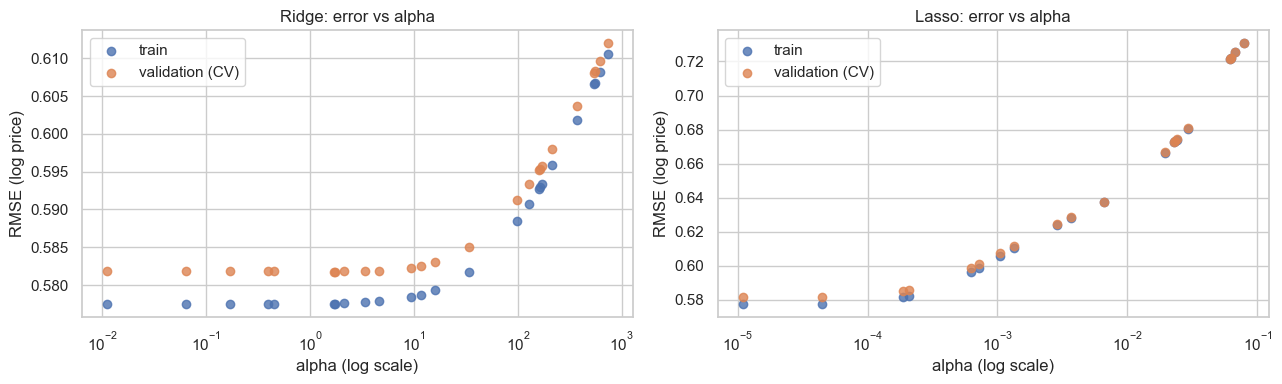

Lasso keeps 346 of 361 features; 15 set to exactly 0


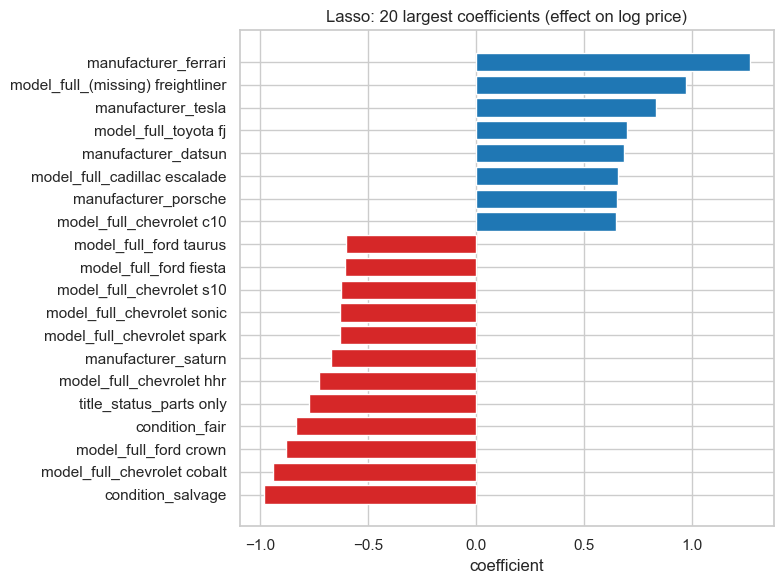

In [9]:
#Linear hyperparameter tuning 

#tries random values for both models
#alpha is the penalty strength
ridge_s = run_search(Ridge(), {"alpha": loguniform(1e-2, 1e3)}, N_ITER["ridge"], Xl_sub, y_sub, cv3, "Ridge", n_jobs=-1)
lasso_s = run_search(Lasso(max_iter=10000), {"alpha": loguniform(1e-5, 1e-1)}, N_ITER["lasso"], Xl_sub, y_sub, cv3, "Lasso", n_jobs=-1)
searches["Ridge"], searches["Lasso"] = ridge_s, lasso_s

#plotting the curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s, nm in zip(axes, [ridge_s, lasso_s], ["Ridge", "Lasso"]):
    r = pd.DataFrame(s.cv_results_); x = r["param_alpha"].astype(float)
    ax.scatter(x, -r["mean_train_score"], label="train", alpha=.8)
    ax.scatter(x, -r["mean_test_score"], label="validation (CV)", alpha=.8)
    ax.set_xscale("log"); ax.set(title=f"{nm}: error vs alpha", xlabel="alpha (log scale)", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()

#selects the best alpha and tests it on all the train data
lasso_full = Lasso(max_iter=10000, **lasso_s.best_params_).fit(Xl_tr, y_tr)
coef = pd.Series(lasso_full.coef_, index=Xl_tr.columns)
print(f"Lasso keeps {(coef != 0).sum()} of {len(coef)} features; {(coef == 0).sum()} set to exactly 0")
#plotting a graph of the best features
top = coef.reindex(coef.abs().sort_values(ascending=False).head(20).index).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "tab:blue", "tab:red"))
ax.set(title="Lasso: 20 largest coefficients (effect on log price)", xlabel="coefficient")
plt.tight_layout(); plt.show()

In [ ]:
results_exp = {'overall': ['Ridge and Lasso reach the same score on the tuning subsample (CV RMSE 0.5818 both), and the same on full train (0.5781)',
             'this is 23% better than the age + odometer line (0.7522) but a typical miss is still about 1.8x in price (e^0.58), so this is still underfitting',
             'train and validation error are only about 0.004 apart for every alpha, so the model is not memorising: the error is bias, not variance',
             'a penalty only fixes variance, which is why tuning alpha cannot help here: the best settings are the weakest penalties'],
 'ridge': ['the curve is flat for alpha below about 10, and then the error rises: more penalty only makes the model more rigid',
           'best alpha 1.69 sits on the flat part, so the default (alpha 1) was already as good (tuning gain: 0.0%)'],
 'lasso': ['the best alpha is 1.1e-5, the lowest value in the search range, and the error rises with every step up in alpha',
           'with a penalty this small Lasso is close to plain linear regression: it keeps 346 of 361 features and drops only 15',
           'so Lasso found nothing to remove: almost every one-hot column carries some signal',
           'Lasso is not worth its cost: 100 s per fit versus 1.0 s for Ridge, for the same score'],
'coefficients': ['the largest Lasso coefficients make sense: Ferrari, Tesla and Porsche raise the price, salvage or fair condition, parts-only titles and cheap models (Cobalt, Spark, Fiesta, Crown) lower it',
                 'a coefficient of 1.0 on log price means about 2.7x the price, all else equal']}

Ridge + splines + interactions: 25 trials x 3 folds in 32s | best CV RMSE 0.5013
   best settings: {'ridge__alpha': np.float64(2.39306404592324)}
Ridge CV RMSE : plain 0.5818 -> enhanced 0.5013 (13.8% better)
enhanced train-val gap: 0.0119  (still small -> still not overfitting)
full-train fit RMSE: 0.4925 | features after expansion: 945


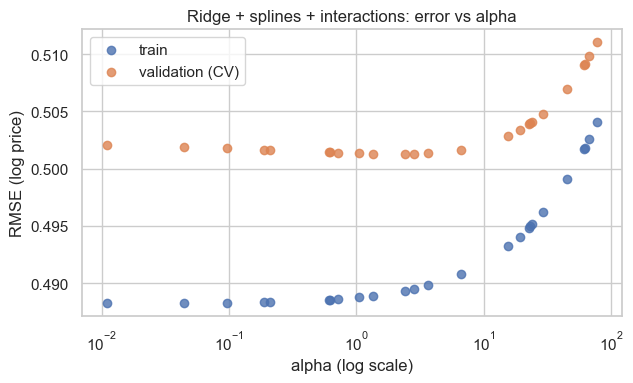

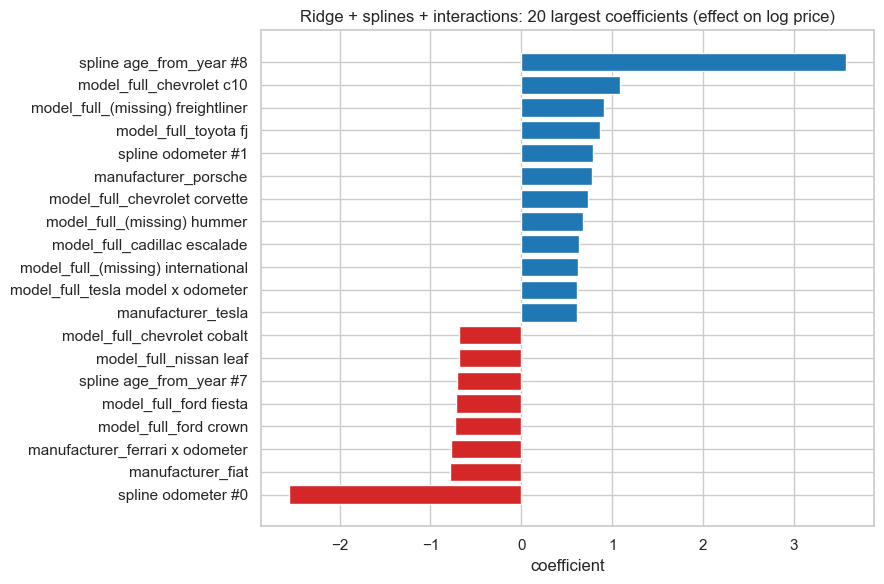

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, SplineTransformer

#main goal is to teach the model that price degradation is non linear
#how: create price into categories and then creats a different rules
NUM_LIN = ["age_from_year", "odometer", "cylinders_num"]
GROUPS = [c for c in Xl_tr.columns if c.startswith(("manufacturer_", "model_", "type_", "fuel_", "drive_", "condition_", "transmission_"))]
G_IDX = [Xl_tr.columns.get_loc(c) for c in GROUPS]
AGE_I, ODO_I = Xl_tr.columns.get_loc("age_from_year"), Xl_tr.columns.get_loc("odometer")

def add_interactions(X):
    #age * odo: Captures how high mileage hurts a newer car differently than an older car
    #g * age: Gives every brand, model and condition its own custom depreciation rate per year
    #g * odo: Gives every category its own custom depreciation rate per mile
    a = np.asarray(X, dtype=np.float32)
    age, odo, g = a[:, [AGE_I]], a[:, [ODO_I]], a[:, G_IDX]
    return np.hstack([a, age * odo, g * age, g * odo])

lin_features = FeatureUnion([
    ("raw_and_interactions", FunctionTransformer(add_interactions)),
    ("splines", ColumnTransformer([("s", SplineTransformer(n_knots=8, degree=3, knots="quantile", include_bias=False), NUM_LIN)])),
])

ridge_plus_s = run_search(Pipeline([("fe", lin_features), ("ridge", Ridge())]),
                          {"ridge__alpha": loguniform(1e-2, 1e2)}, N_ITER["ridge"], Xl_sub, y_sub, cv3, "Ridge + splines + interactions", n_jobs=-1)

old_best, new_best = -ridge_s.best_score_, -ridge_plus_s.best_score_
bi = ridge_plus_s.best_index_
print(f"Ridge CV RMSE : plain {old_best:.4f} -> enhanced {new_best:.4f} ({100 * (old_best - new_best) / old_best:.1f}% better)")
print(f"enhanced train-val gap: {-ridge_plus_s.cv_results_['mean_test_score'][bi] + ridge_plus_s.cv_results_['mean_train_score'][bi]:.4f}"
      f"  (still small -> still not overfitting)")

ridge_plus = Pipeline([("fe", lin_features), ("ridge", Ridge(alpha=ridge_plus_s.best_params_["ridge__alpha"]))]).fit(Xl_tr, y_tr)
print(f"full-train fit RMSE: {root_mean_squared_error(y_tr, ridge_plus.predict(Xl_tr)):.4f} | features after expansion: {ridge_plus[-1].coef_.shape[0]}")

r = pd.DataFrame(ridge_plus_s.cv_results_); x = r["param_ridge__alpha"].astype(float)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(x, -r["mean_train_score"], label="train", alpha=.8)
ax.scatter(x, -r["mean_test_score"], label="validation (CV)", alpha=.8)
ax.set_xscale("log"); ax.set(title="Ridge + splines + interactions: error vs alpha", xlabel="alpha (log scale)", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()
n_spl = ridge_plus[-1].coef_.shape[0] - (Xl_tr.shape[1] + 1 + 2 * len(GROUPS))     #spline columns = whatever is left over
feat_names = (list(Xl_tr.columns) + ["age_x_odometer"] + [f"{c} x age" for c in GROUPS] + [f"{c} x odometer" for c in GROUPS]
              + [f"spline {c} #{i}" for c in NUM_LIN for i in range(n_spl // len(NUM_LIN))])
assert len(feat_names) == ridge_plus[-1].coef_.shape[0], "feature names out of step with the coefficients"
coef_plus = pd.Series(ridge_plus[-1].coef_, index=feat_names)
top = coef_plus.reindex(coef_plus.abs().sort_values(ascending=False).head(20).index).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "tab:blue", "tab:red"))
ax.set(title="Ridge + splines + interactions: 20 largest coefficients (effect on log price)", xlabel="coefficient")
plt.tight_layout(); plt.show()


In [12]:
results_exp = {'change': ['Ridge got two extra kinds of features',
            '(1) interactions: age x odometer, plus each brand / model / type / condition x age and x odometer',
            '(2) splines on age, odometer and cylinders',
            'this lets the model learn that cars lose value along a curve, not a straight line, and that each brand loses value at its own speed'],
 'result': ['validation RMSE dropped from 0.5818 to 0.5013 (13.8% better) on the tuning subsample',
            'on full train with 5 folds: 0.5781 -> 0.4957 (CV) and 0.5804 -> 0.4977 (test)',
            'best alpha 2.39; the 945 expanded features were needed, the gain came from the features and not from the alpha'],
 'overfitting check': ['train and validation error are only 0.0119 apart, so the model is not memorising even with 945 features'],
 'coefficients': ['the largest coefficients are age and odometer spline pieces, so the age and mileage curves are where the gain comes from',
                  'spline columns overlap each other, so their individual values (for example +3.6 for the newest-age piece) cannot be read alone, only together',
                  'brand and model terms behave as expected: C10, Corvette and Porsche up, Cobalt, Fiesta and Crown down'],
 'limit': ['a RMSE of about 0.50 is still large: a straight-line model with extra features is still too simple for this data, some underfitting remains',
           'it already beats a single tuned decision tree (0.4957 vs 0.5362 CV), which shows how much of the price pattern is the non-linear depreciation'],
 'next': 'tree models (Random Forest, XGBoost) should find these curves and interactions on their own, without hand-made features'}

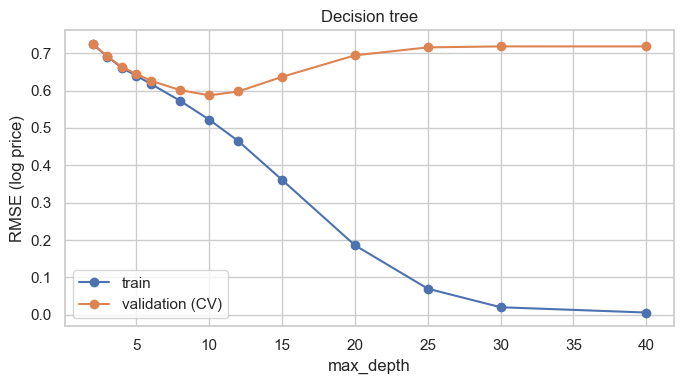

Decision Tree grid: 56 combos x 3 folds in 3s | best CV RMSE 0.5722 | best settings: {'max_depth': 15, 'min_samples_leaf': 30}


,max_depth,min_samples_leaf,val_rmse,train_rmse,overfit_gap
38,15,30,0.5722,0.5219,0.0503
46,20,30,0.5723,0.5208,0.0515
54,25,30,0.5723,0.5208,0.0515
28,12,20,0.5726,0.5242,0.0484
37,15,25,0.5734,0.5140,0.0595


In [13]:
#testing different depth
depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40]
#train and validation scores
tr_sc, va_sc = validation_curve(DecisionTreeRegressor(random_state=SEED), Xt_sub, y_sub, param_name="max_depth",
                                param_range=depths, cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, -tr_sc.mean(1), "o-", label="train")
ax.plot(depths, -va_sc.mean(1), "o-", label="validation (CV)")
ax.set(title="Decision tree", xlabel="max_depth", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()

#the min_samples_leaf is the min number of training rows inside each leaf
t0 = time.time()
dt_s = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                    {"max_depth": [6, 8, 10, 12, 15, 20, 25], "min_samples_leaf": [1, 3, 5, 10, 20, 25, 30, 40]},
                    cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True, refit=False)
dt_s.fit(Xt_sub, y_sub)
searches["Decision Tree"] = dt_s
print(f"Decision Tree grid: {len(dt_s.cv_results_['params'])} combos x 3 folds in {time.time() - t0:.0f}s | "
      f"best CV RMSE {-dt_s.best_score_:.4f} | best settings: {dt_s.best_params_}")
display(top_trials(dt_s))

In [14]:
results_exp = {'best parameters': 'depth 15 and min_samples_leaf 30 (CV RMSE 0.5722 on the subsample, train-validation gap 0.05)',
 'depth curve': ['with the default leaf size (1) validation error is lowest around depth 10 (about 0.59) and then gets worse',
                 'train error falls to almost 0 after depth 25: the tree memorises every row',
                 'beyond depth 25 the validation error stops at about 0.72, the same as the untuned tree'],
 'findings': ['leaf size matters more than depth: forcing at least 30 rows per leaf stops the tree memorising, and lets it go deeper '
              'without harm',
              'the top settings are a tie (0.5722 vs 0.5723), so the exact depth is not important',
              'tuning cut the train-validation gap from 0.71 to 0.05, a 20% error reduction',
              'the tree beats Ridge and Lasso (0.5722 vs 0.5818) but not Ridge with splines and interactions (0.5013)',
              'on full train: CV 0.5362, test 0.5304; a single tree is the weakest tree model and acts as the control for the ensembles'],
 'caveat': 'tuning used a 60k subsample, so the best leaf size may be a bit different on the full 184k rows'}

Random Forest: 140 trials x 3 folds in 568s | best CV RMSE 0.4883
   best settings: {'max_depth': 30, 'max_features': 0.3, 'max_samples': np.float64(0.7831225724502406), 'min_samples_leaf': 1}


,max_depth,max_features,max_samples,min_samples_leaf,val_rmse,train_rmse,overfit_gap
84,30.0000,0.3000,0.7831,1,0.4883,0.2274,0.2609
95,NaN,0.5000,0.7341,1,0.4922,0.2393,0.2528
118,30.0000,0.3000,0.5716,1,0.4923,0.2811,0.2112
125,20.0000,0.3000,0.7115,1,0.4931,0.2800,0.2131
108,30.0000,0.3000,0.5400,1,0.4935,0.2907,0.2028


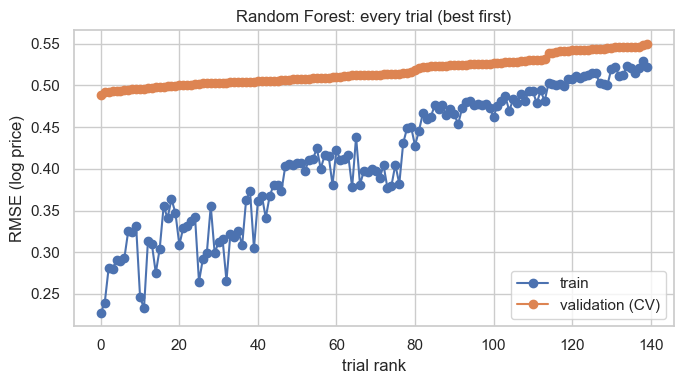

In [15]:
#random forest
rf_space = {
    #how closely the tree memorizes data
    "max_depth": [10, 15, 20, 30, None], 
    "min_samples_leaf": [1, 2, 5, 10],
    #fraction of columns tried at each split
    "max_features": [0.3, 0.5, 0.7, 1.0],
    #fraction of rows per tree
    "max_samples": uniform(0.5, 0.3)}
rf_s = run_search(RandomForestRegressor(n_estimators=RF_SEARCH_TREES, n_jobs=-1, random_state=SEED),
                  rf_space, 140, Xt_sub, y_sub, cv3, "Random Forest")
searches["Random Forest"] = rf_s
display(top_trials(rf_s))
plot_trials(rf_s, "Random Forest")

In [ ]:
results_exp = ['best CV RMSE 0.4883, which is 15% better than the tuned single tree (0.5722): averaging many trees removes the noise of one tree',
 'all the top results favour deep trees with small leaves (leaf 1 or 2)',
 'the noticeable train-validation gap (about 0.26) is normal for deep trees that are averaged, each tree memorises but the average does not',
 'max_features 0.3 (5 of the 18 columns) was the lowest value tried, so a smaller one might be better: tested in the next search, it was not']

Random Forest 2: 140 trials x 3 folds in 373s | best CV RMSE 0.4877
   best settings: {'max_depth': 40, 'max_features': 5, 'max_samples': np.float64(0.8565564276029283), 'min_samples_leaf': 1}
search 1 CV RMSE 0.4883 | search 2 CV RMSE 0.4877 -> keeping search 2: {'max_depth': 40, 'max_features': 5, 'max_samples': np.float64(0.8565564276029283), 'min_samples_leaf': 1}


,max_depth,max_features,max_samples,min_samples_leaf,val_rmse,train_rmse,overfit_gap
99,40.0000,5,0.8566,1,0.4877,0.2104,0.2773
87,30.0000,5,0.7718,1,0.4886,0.2300,0.2586
98,30.0000,4,0.8299,1,0.4886,0.2173,0.2714
92,NaN,3,0.9503,1,0.4887,0.1923,0.2965
94,NaN,7,0.8902,1,0.4888,0.2040,0.2848


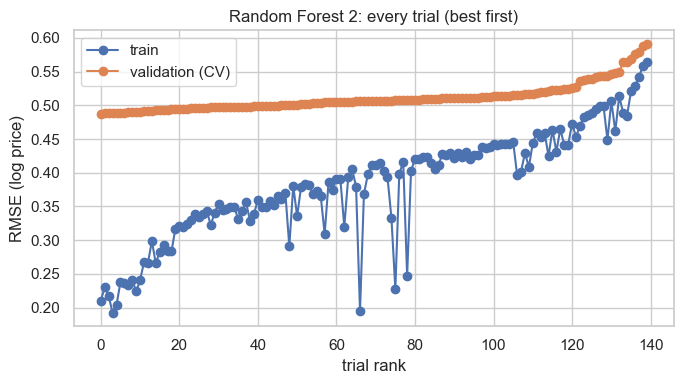

In [17]:
#random forest 2
#run the first random forest cell before this one: it keeps that result and only replaces it if this search is better
rf1_s = rf_s
rf_space = {
    #how closely the tree memorizes data (beyond ~40 nothing changes with leaf >= 2, so the list stops there)
    "max_depth": [15, 20, 30, 40, None],
    "min_samples_leaf": [1, 2, 3, 5],
    #columns tried at each split, as a count of the 18 features (a fraction like 0.001 or 0.1 would both round to 1)
    #search 1 won at 0.3 = 5 features, the lowest value it tried, so this goes below and around it
    "max_features": [1, 2, 3, 4, 5, 7, 9],
    #fraction of rows per tree (search 1 won at 0.75, near the old upper limit of 0.8, so the range now reaches 1.0)
    "max_samples": uniform(0.5, 0.5)}
rf2_s = run_search(RandomForestRegressor(n_estimators=RF_SEARCH_TREES, n_jobs=-1, random_state=SEED),
                   rf_space, 140, Xt_sub, y_sub, cv3, "Random Forest 2")
#best_score_ is a negative RMSE, so the higher one is the better one
rf_s = rf2_s if rf2_s.best_score_ > rf1_s.best_score_ else rf1_s
print(f"search 1 CV RMSE {-rf1_s.best_score_:.4f} | search 2 CV RMSE {-rf2_s.best_score_:.4f} -> "
      f"keeping search {'2' if rf_s is rf2_s else '1'}: {rf_s.best_params_}")
searches["Random Forest"] = rf_s
display(top_trials(rf2_s))
plot_trials(rf2_s, "Random Forest 2")

In [18]:
results_exp = {
    'search 1 (first RF cell, 140 trials)': [
        'best CV RMSE 0.4883: max_depth 30, min_samples_leaf 1, max_features 0.3 (5 of 18 columns), max_samples 0.78',
        'an earlier run with 40 trials only reached 0.4954 and picked leaf 2, so the extra trials found the better leaf size',
        'train RMSE 0.2274, gap 0.26: the forest memorises its own rows, which is normal for deep trees that are averaged',
    ],
    'search 2 (second cell, 140 trials)': [
        'changes: max_features as counts (1 to 9) because fractions like 0.001 and 0.1 both round to 1 column, max_samples range widened to 1.0',
        'best CV RMSE 0.4877: max_depth 40, min_samples_leaf 1, max_features 5, max_samples 0.86',
        'train RMSE 0.2104, gap 0.28: slightly more memorising than search 1',
        'the top 5 trials are within 0.0011 of each other (0.4877 to 0.4888), so many settings are equally good',
    ],
    'comparison': [
        'search 2 beats search 1 by only 0.0006, far below the fold noise (about 0.005), so the two searches are a tie',
        'the wider space did not help: the gain over the 40-trial run came from searching more, not from the new ranges',
        'both agree on the shape of the best forest: about 5 columns per split, leaf size 1, very deep trees, 75 to 85% of the rows per tree',
        'max_features 1 to 3 never reach the top trials, so the idea that an even smaller value could help was wrong',
        'the search has reached a plateau, more trials or wider ranges are unlikely to help',
        'on full train with 5 folds the final forest scores CV 0.4501 and test 0.4455, better than every linear model and the tree, but not than XGBoost',
    ]
}

categorical check -> dtype: category | levels: 4278
XGBoost A (codes as numbers): 40 trials x 3 folds in 160s | best CV RMSE 0.4492
   best settings: {'colsample_bytree': np.float64(0.817346339912409), 'max_depth': 10, 'min_child_weight': 11, 'reg_alpha': np.float64(0.2892025772815462), 'reg_lambda': np.float64(14.913689591550755), 'subsample': np.float64(0.9489310981492397)}
XGBoost B (native categorical): 40 trials x 3 folds in 671s | best CV RMSE 0.4375
   best settings: {'colsample_bytree': np.float64(0.4851189278060578), 'max_cat_threshold': 256, 'max_depth': 8, 'min_child_weight': 7, 'reg_alpha': np.float64(1.4221435917997072), 'reg_lambda': np.float64(1.010873234599077), 'subsample': np.float64(0.9104282083222373)}

A = 0.4492 | B = 0.4375 -> keeping variant B (native categorical)


,colsample_bytree,max_cat_threshold,max_depth,min_child_weight,reg_alpha,reg_lambda,subsample,val_rmse,train_rmse,overfit_gap
26,0.4851,256,8,7,1.4221,1.0109,0.9104,0.4375,0.2353,0.2022
10,0.3779,256,9,2,3.6461,6.7144,0.9152,0.4382,0.3068,0.1314
38,0.8198,128,10,3,1.9919,3.3069,0.7730,0.4408,0.1617,0.2790
19,0.4567,256,9,7,0.1852,56.7747,0.8997,0.4412,0.2241,0.2170
0,0.5233,64,7,7,0.0336,28.3527,0.9927,0.4415,0.2716,0.1698


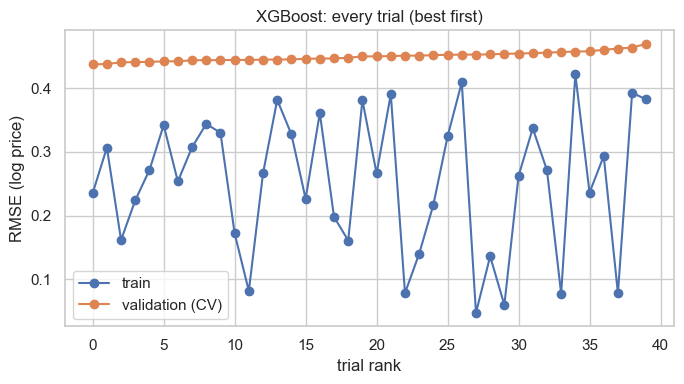

In [19]:
#XGBoost
cat_types = {c: pd.CategoricalDtype(sorted(set(Xt_tr.loc[Xt_tr[c] >= 0, c]))) for c in CAT_COLS}

def to_cat(X):
    out = X.copy()
    for c in CAT_COLS:
        valid = out[c].where(out[c] >= 0)                       # -1 (unseen) -> NaN
        out[c] = pd.Categorical(valid, dtype=cat_types[c])
    return out

Xc_sub = to_cat(Xt_sub)
print("categorical check -> dtype:", Xc_sub["model_full"].dtype.name, "| levels:", len(cat_types["model_full"].categories))

xgb_space = {"max_depth": randint(4, 13), "min_child_weight": randint(1, 21), "subsample": uniform(0.6, 0.4),
             "colsample_bytree": uniform(0.3, 0.7), "reg_lambda": loguniform(0.1, 300), "reg_alpha": loguniform(1e-3, 10)}
#max_cat_threshold = how many of the 4,278 model_full levels one split may group on one side, only means something for native categoricals
xgb_space_b = {**xgb_space, "max_cat_threshold": [64, 128, 256]}

def make_xgb(cat, **kw):
    return xgb.XGBRegressor(tree_method="hist", enable_categorical=cat, n_jobs=-1, random_state=SEED, **kw)

#label codes are used as plain numbers
xgb_a = run_search(make_xgb(False, n_estimators=XGB_SEARCH_TREES, learning_rate=0.1),
                   xgb_space, N_ITER["xgb"], Xt_sub, y_sub, cv3, "XGBoost A (codes as numbers)")
#the 11 categorical columns become pandas category and XGBoost native categorical splitting is used
xgb_b = run_search(make_xgb(True, n_estimators=XGB_SEARCH_TREES, learning_rate=0.1),
                   xgb_space_b, N_ITER["xgb"], Xc_sub, y_sub, cv3, "XGBoost B (native categorical)")

use_cat = (-xgb_b.best_score_) < (-xgb_a.best_score_)
xgb_s = xgb_b if use_cat else xgb_a
XGB_KEY = "trees_cat" if use_cat else "trees"
searches["XGBoost"] = xgb_s
print(f"\nA = {-xgb_a.best_score_:.4f} | B = {-xgb_b.best_score_:.4f} -> keeping variant {'B (native categorical)' if use_cat else 'A (codes as numbers)'}")
display(top_trials(xgb_s))
plot_trials(xgb_s, "XGBoost")

In [20]:
results_exp = {'A vs B': ['A (label codes as plain numbers): CV RMSE 0.4492, 160 s. B (native categorical splits): CV RMSE 0.4375, 671 s',
            'B is 2.6% better, which is about twice the normal fold noise (about 0.006), so it is a small but probably real gain',
            'B is 4.2x slower, which is the price of letting a split group many of the 4,278 model_full levels together instead of cutting '
            'at an arbitrary code number',
            'B was kept because it has the lower RMSE'],
 'best parameters (B)': ['depth 8, min_child_weight 7, colsample 0.49, lambda 1.0, alpha 1.4, max_cat_threshold 256',
                         'max_cat_threshold 256 is the largest value tried, so a bigger one might help a little'],
 'comparison': ['0.4375 is the best score so far: 10% better than the Random Forest (0.4877) on the same subsample and folds',
                'boosting builds each tree on the errors of the previous ones, which also reduces bias, while a forest only averages',
                'the untuned XGBoost scored 0.4823 and the tuned one 0.4375, so tuning gave a 9.3% gain (see the tuning table below)']}

early stopping: best round 2875 of max 4000 (26s) | validation RMSE 0.3916 -> final model uses 3162 trees


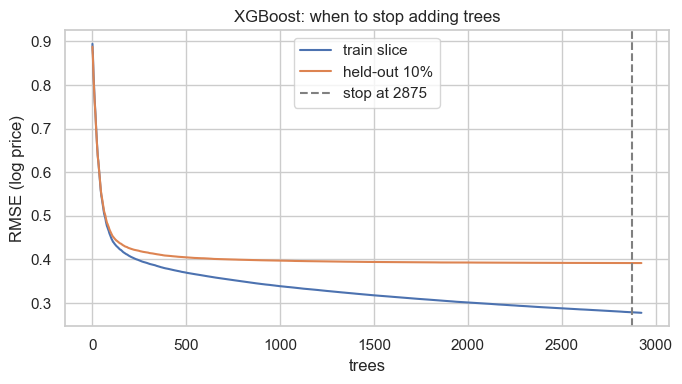

In [21]:
X_full = to_cat(Xt_tr) if use_cat else Xt_tr
Xa, Xb, ya, yb = train_test_split(X_full, y_tr, test_size=0.10, random_state=SEED)

best_xgb_params = dict(xgb_s.best_params_)
es = make_xgb(use_cat, n_estimators=XGB_MAX_TREES, learning_rate=0.03, early_stopping_rounds=50, **best_xgb_params)
t0 = time.time()
es.fit(Xa, ya, eval_set=[(Xa, ya), (Xb, yb)], verbose=False)
hist = es.evals_result()
n_best = es.best_iteration + 1
N_FINAL_TREES = int(n_best * 1.1)
print(f"early stopping: best round {n_best} of max {XGB_MAX_TREES} ({time.time() - t0:.0f}s) | "
      f"validation RMSE {min(hist['validation_1']['rmse']):.4f} -> final model uses {N_FINAL_TREES} trees")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["validation_0"]["rmse"], label="train slice")
ax.plot(hist["validation_1"]["rmse"], label="held-out 10%")
ax.axvline(n_best, color="grey", ls="--", label=f"stop at {n_best}")
ax.set(title="XGBoost: when to stop adding trees", xlabel="trees", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()

xgb_final = make_xgb(use_cat, n_estimators=N_FINAL_TREES, learning_rate=0.03, **best_xgb_params)

In [ ]:
results_exp = ['the learning rate was lowered from 0.1 to 0.03, so the model needs many more trees; early stopping picked round 2875 of a maximum of 4000',
 'so the cap of 4000 was never reached and the model did stop by itself: the final model uses 3162 trees (10% more, because the final fit sees all the data, not 90%)',
 'validation RMSE on the held-out 10% reached 0.3916; train RMSE kept falling (to about 0.28) while validation went almost flat after about 1000 trees (0.397 -> 0.392)',
 'the trees after 1000 add only about 0.005 in total, while the train-validation gap keeps widening, so early stopping is what decides when more trees stop being worth it',
 '0.3916 cannot be compared with 0.4375 from the search: it uses 166k rows instead of 40k per fold, a lower learning rate and a different split']

In [23]:
#showing the difference between the tuned vs plain models
def default_model(name):
    return {"Ridge": Ridge(), "Lasso": Lasso(max_iter=10000),
            "Decision Tree": DecisionTreeRegressor(random_state=SEED),
            "Random Forest": RandomForestRegressor(n_estimators=RF_SEARCH_TREES, n_jobs=-1, random_state=SEED),
            "XGBoost": make_xgb(use_cat)}[name]

sub_data = {"Ridge": Xl_sub, "Lasso": Xl_sub, "Decision Tree": Xt_sub, "Random Forest": Xt_sub,
            "XGBoost": Xc_sub if use_cat else Xt_sub}
rows = []
for name, s in searches.items():
    d, _ = cv_oof(default_model(name), sub_data[name], y_sub, cv3)
    bi = s.best_index_
    tuned_val, tuned_tr = -s.cv_results_["mean_test_score"][bi], -s.cv_results_["mean_train_score"][bi]
    rows.append({"model": name, "default_val_rmse": d["cv_rmse"], "tuned_val_rmse": tuned_val,
                 "improvement_%": 100 * (d["cv_rmse"] - tuned_val) / d["cv_rmse"],
                 "default_gap": d["cv_rmse"] - d["train_rmse"], "tuned_gap": tuned_val - tuned_tr})
tuning_gain = pd.DataFrame(rows).set_index("model")
display(tuning_gain)

,default_val_rmse,tuned_val_rmse,improvement_%,default_gap,tuned_gap
model,,,,,
Ridge,0.5818,0.5818,-0.0003,0.0043,0.0042
Lasso,0.9053,0.5818,35.7362,-0.0000,0.0043
Decision Tree,0.7183,0.5722,20.3312,0.7124,0.0503
Random Forest,0.5010,0.4877,2.6649,0.3134,0.2773
XGBoost,0.4823,0.4375,9.2807,0.2489,0.2022


In [ ]:
results_exp = {'what the table shows': 'validation RMSE of each model with default settings vs tuned settings, on the same 60k subsample and the same 3 folds',
 'Ridge': 'no gain (-0.0003%): the default alpha 1 is already on the flat part of the curve',
 'Lasso': ["the 35.7% 'gain' is not a real improvement: the default alpha of 1 is so strong that Lasso sets every coefficient to 0 and "
           'predicts one constant (0.9053, the same as the dummy)',
           'tuning only moved alpha down to a usable value (0.5818)'],
 'Decision Tree': '20.3% gain: an untuned tree is grown until each leaf holds one row, so it memorises (gap 0.71); tuning cut the gap to 0.05',
 'Random Forest': 'only 2.7% gain: averaging protects a forest against overfitting, so the defaults were already decent; the gap stays large (0.31 -> 0.28) and that is expected',
 'XGBoost': '9.3% gain, the biggest real gain: boosting is easy to overfit, so depth, regularisation and column sampling matter',
 'takeaway': ['tuning matters most for models with a strong overfitting knob (tree, XGBoost) and least for Ridge and the forest',
              'tuning never changed the order of the tree models: XGBoost has the lowest error, then Random Forest, then Decision Tree, both before and after',
              'Ridge + splines + interactions is not in this table: its gain came from new features, shown above']}

In [25]:
#loading the test datasets
test_trees = pd.read_parquet("prepared/trees_test.parquet")
test_lin = pd.read_parquet("prepared/linear_test.parquet")
if QUICK:
    keep = test_trees.sample(TEST_N, random_state=SEED).index
    test_trees, test_lin = test_trees.loc[keep], test_lin.loc[keep]
Xt_te, y_te, p_te = split_xy(test_trees)
Xl_te, y_l_te, _ = split_xy(test_lin)
Xl_te = Xl_te[Xl_tr.columns]; Xt_te = Xt_te[Xt_tr.columns]            # same column order as train
assert Xt_te.index.equals(Xl_te.index) and np.allclose(y_te, y_l_te)
assert Xt_te.isna().sum().sum() == 0 and Xl_te.isna().sum().sum() == 0

TEST = {"linear": Xl_te, "linear_age": Xl_te[["age_from_year", "odometer"]], "trees": Xt_te}
TRAIN["trees_cat"], TEST["trees_cat"] = to_cat(Xt_tr), to_cat(Xt_te)
print(f"test rows: {len(Xt_te):,} | test cells with an unseen category (code -1): {int((Xt_te[CAT_COLS] == -1).sum().sum())}")

spec = [
    ("Dummy (median)", DummyRegressor(strategy="median"), "linear_age"),
    ("Linear (age, odometer)", LinearRegression(), "linear_age"),
    ("Ridge", Ridge(**ridge_s.best_params_), "linear"),
    ("Ridge + splines + interactions", Pipeline([("fe", lin_features), ("ridge", Ridge(alpha=ridge_plus_s.best_params_["ridge__alpha"]))]), "linear"),
    ("Lasso", Lasso(max_iter=10000, **lasso_s.best_params_), "linear"),
    ("Decision Tree", DecisionTreeRegressor(random_state=SEED, **dt_s.best_params_), "trees"),
    ("Random Forest", RandomForestRegressor(n_estimators=RF_FINAL_TREES, n_jobs=-1, random_state=SEED, **rf_s.best_params_), "trees"),
    ("XGBoost", xgb_final, XGB_KEY),
]

boot_rng = np.random.default_rng(SEED)
def bootstrap_rmse_ci(resid, n_boot=1000):
    n = len(resid)
    vals = [np.sqrt(np.mean(resid[boot_rng.integers(0, n, n)] ** 2)) for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5])

#for every model, in this order: 5-fold CV on train -> refit on all of train -> ONE prediction on the test set
fitted, oof_preds, test_preds, data_key, rows = {}, {}, {}, {}, []
for name, est, key in spec:
    t0 = time.time()
    cv_stats, oof = cv_oof(est, TRAIN[key], y_tr, cv5)
    model = clone(est).fit(TRAIN[key], y_tr)
    pred = model.predict(TEST[key])
    ev = evaluate(y_te, pred, p_te)
    lo, hi = bootstrap_rmse_ci(np.asarray(y_te) - pred)
    fitted[name], oof_preds[name], test_preds[name], data_key[name] = model, oof, pred, key
    rows.append({"model": name, **cv_stats, "test_rmse_log": ev["rmse_log"], "ci_low": lo, "ci_high": hi,
                 "test_r2_log": ev["r2_log"], "test_mae_usd": ev["mae_usd"], "test_rmse_usd": ev["rmse_usd"],
                 "test_mdape_pct": ev["mdape_pct"], "z_gap": (ev["rmse_log"] - cv_stats["cv_rmse"]) / max(cv_stats["cv_std"], 1e-9)})
    print(f"{name:32s} cv {cv_stats['cv_rmse']:.4f} +/- {cv_stats['cv_std']:.4f} | test {ev['rmse_log']:.4f} | {time.time() - t0:.0f}s")

results = pd.DataFrame(rows).set_index("model").sort_values("cv_rmse")
display(results)
BEST = results.index[0]                                   # chosen by CV, never by test
print(f"\nbest model by cross-validation: {BEST}")

test rows: 46,002 | test cells with an unseen category (code -1): 547
Dummy (median)                   cv 0.9068 +/- 0.0015 | test 0.9083 | 0s
Linear (age, odometer)           cv 0.7522 +/- 0.0027 | test 0.7547 | 0s
Ridge                            cv 0.5781 +/- 0.0050 | test 0.5804 | 6s
Ridge + splines + interactions   cv 0.4957 +/- 0.0047 | test 0.4977 | 18s
Lasso                            cv 0.5781 +/- 0.0050 | test 0.5804 | 592s
Decision Tree                    cv 0.5362 +/- 0.0047 | test 0.5304 | 3s
Random Forest                    cv 0.4501 +/- 0.0052 | test 0.4455 | 76s
XGBoost                          cv 0.4020 +/- 0.0064 | test 0.3991 | 171s


,cv_rmse,cv_std,train_rmse,fit_s,test_rmse_log,ci_low,ci_high,test_r2_log,test_mae_usd,test_rmse_usd,test_mdape_pct,z_gap
model,,,,,,,,,,,,
XGBoost,0.4020,0.0064,0.2658,28.2195,0.3991,0.3902,0.4082,0.8056,"2,960.9790","5,917.5889",13.8968,-0.4517
Random Forest,0.4501,0.0052,0.1925,12.7400,0.4455,0.4368,0.4539,0.7577,"3,456.9846","6,755.1219",16.5411,-0.8850
Ridge + splines + interactions,0.4957,0.0047,0.4922,2.9372,0.4977,0.4875,0.5078,0.6976,"3,886.7613","7,373.6918",17.9354,0.4449
Decision Tree,0.5362,0.0047,0.4998,0.4634,0.5304,0.5214,0.5394,0.6565,"4,530.1555","7,988.5460",22.9856,-1.2257
Ridge,0.5781,0.0050,0.5768,1.0111,0.5804,0.5718,0.5900,0.5888,"4,952.4574","8,550.4852",24.5520,0.4564
Lasso,0.5781,0.0050,0.5768,99.9110,0.5804,0.5719,0.5896,0.5888,"4,953.0171","8,553.1135",24.5719,0.4591
"Linear (age, odometer)",0.7522,0.0027,0.7522,0.0082,0.7547,0.7473,0.7626,0.3046,"7,358.5976","11,776.9127",41.0316,0.9373
Dummy (median),0.9068,0.0015,0.9068,0.0068,0.9083,0.9021,0.9147,-0.0070,"9,567.8822","14,105.9601",55.9096,0.9765



best model by cross-validation: XGBoost


In [26]:
results_exp = {'ranking (5-fold CV on full train, test used once)': 
               ['XGBoost 0.4020 (test 0.3991) < Random Forest 0.4501 < Ridge + splines + interactions 0.4957 < Decision Tree 0.5362 < Ridge = Lasso 0.5781 < Linear 0.7522 < Dummy 0.9068',
                'XGBoost is the best model and it was chosen by CV not by test',
                'the order is the same on test, and the 95% bootstrap intervals of XGBoost (0.390 to 0.408), Random Forest (0.437 to 0.454) and Ridge + splines (0.488 to 0.508) do not overlap, so those three steps are real',
                'Ridge and Lasso are identical (0.5804 test, intervals overlap fully): there is no reason to pick Lasso which is also about 100x slower'],
 'what each step bought (CV RMSE)': ['Dummy -> Linear (age, odometer): -17%',
                                     'Linear -> Ridge (all features): -23%',
                                     'Ridge -> Ridge + splines + interactions: -14%',
                                     'Ridge + splines -> Random Forest: -9%',
                                     'Random Forest -> XGBoost: -11%',
                                     'XGBoost vs the dummy: -56%'],
 'overfitting': ['train vs CV RMSE: Ridge + splines 0.4922 vs 0.4957 (no gap), Decision Tree 0.4998 vs 0.5362, XGBoost 0.2658 vs 0.4020 Random Forest 0.1925 vs 0.4501',
                 'the forest and XGBoost have a big train-validation gap, but their CV and test scores are the best, so the gap is not '
                 'hurting: judge by validation, not by the gap'],
 'test vs CV (leakage alarm)': ['z_gap is between -1.23 and +0.98 for every model, well under 2, so there is no sign of leakage or of '
                                'tuning to the folds',
                                'the test score is a little lower than CV for the tree models (negative z_gap): the final fit sees 100% of '
                                'train, while a CV fit sees 80%'],
 'in dollars (XGBoost on test)': ['R2 0.81: the model explains 81% of the variation in log price',
                                  'MAE $2,961  and MdAPE 13.9% (half of the cars are within 14%)',
                                  'RMSE $5,918 is double the MAE because a few big misses on expensive cars count a lot; the dollar error is dominated by the expensive tail',
                                  'the linear models miss by about $5,000 on average and 25% typically; the dummy by $9,568 and 56%'],
 'cost': ['XGBoost is the slowest of the tree models (28 s per CV fold vs 13 s for the forest and 2.9 s for Ridge + splines); Lasso is the slowest overall (100 s per fold)',
          'Ridge + splines + interactions is only 0.046 RMSE behind the forest for about 1/4 of the time and stays readable, so it is the best choice if speed or explanation matters'],
 'chart': 'the CV bars and test bars have nearly the same height for every model and the error bars of neighbouring models mostly do not overlap which confirms the ranking'}

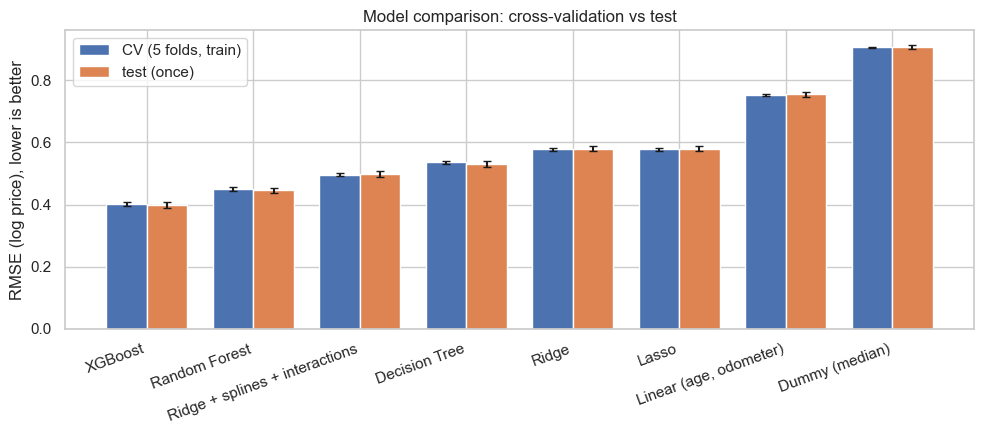

In [27]:
order = results.index.tolist()
x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w / 2, results["cv_rmse"], w, yerr=results["cv_std"], label="CV (5 folds, train)", capsize=3)
ax.bar(x + w / 2, results["test_rmse_log"], w, label="test (once)",
       yerr=[results["test_rmse_log"] - results["ci_low"], results["ci_high"] - results["test_rmse_log"]], capsize=3)
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20, ha="right")
ax.set(ylabel="RMSE (log price), lower is better", title="Model comparison: cross-validation vs test")
ax.legend(); plt.tight_layout(); plt.show()

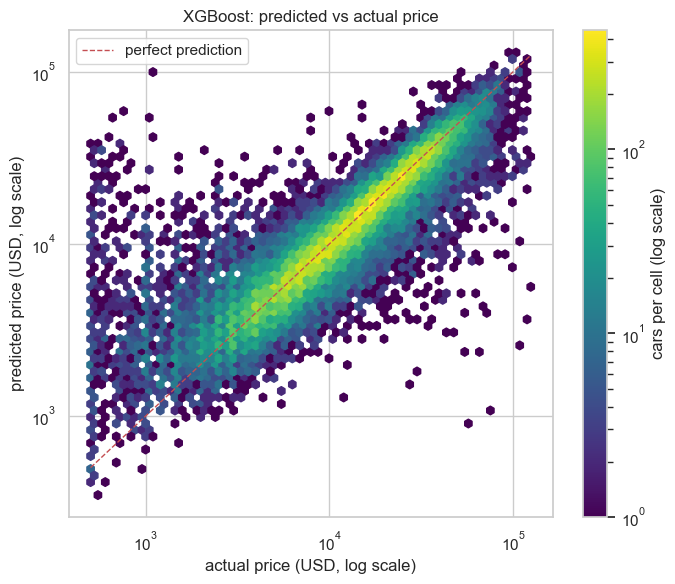

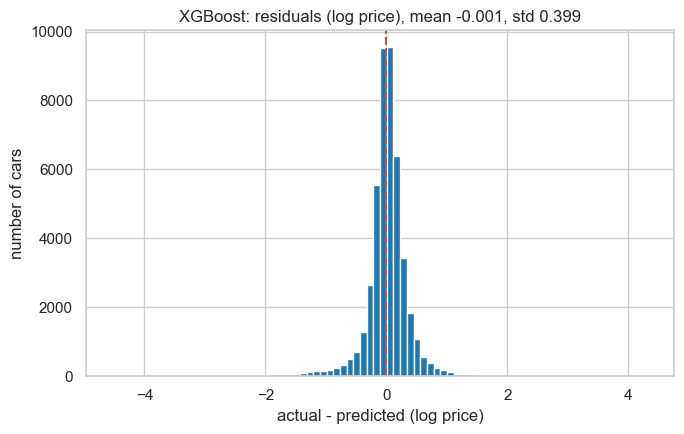

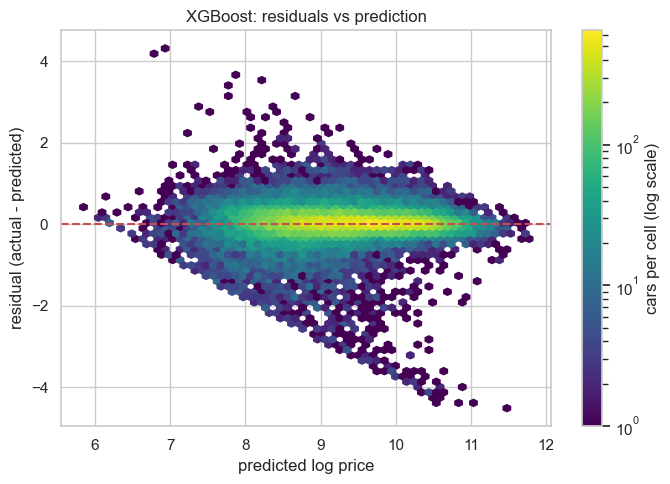

,n,mae_usd,mdape_pct,bias_log
price band,,,,
<5k,"9,080.0000","1,650.5007",24.9203,-0.2918
5-15k,"19,055.0000","1,709.6305",13.4528,0.0427
15-30k,"12,007.0000","3,211.9603",10.7557,0.0703
>30k,"5,860.0000","8,546.3128",12.7860,0.1637


,n,mae_usd,mdape_pct,bias_log
car age (years),,,,
0-3,"6,020.0000","5,351.0637",10.5037,-0.0093
4-6,"8,499.0000","3,499.8736",10.8607,0.0117
7-10,"11,127.0000","2,356.3069",12.0837,-0.0011
11-15,"9,941.0000","1,803.0537",14.6640,-0.0090
16-25,"7,561.0000","2,050.8504",21.8239,0.0004
>25,"2,854.0000","5,116.6300",33.6570,0.0077


,n,mae_usd,mdape_pct,bias_log
seller,,,,
Carvana ads,"1,809.0000","2,634.9479",7.6070,0.0010
other ads,"44,193.0000","2,974.3248",14.2890,-0.0008


In [28]:
best_model, key = fitted[BEST], data_key[BEST]
pred_log = test_preds[BEST]
resid = np.asarray(y_te) - pred_log
usd_pred = np.exp(pred_log)
fig, ax = plt.subplots(figsize=(7, 6))
hb = ax.hexbin(p_te, usd_pred, gridsize=60, bins="log", cmap="viridis", mincnt=1, xscale="log", yscale="log")
lim = [p_te.min(), p_te.max()]; ax.plot(lim, lim, "r--", lw=1, label="perfect prediction")
ax.set(title=f"{BEST}: predicted vs actual price", xlabel="actual price (USD, log scale)", ylabel="predicted price (USD, log scale)")
fig.colorbar(hb, ax=ax, label="cars per cell (log scale)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(resid, bins=80, color="tab:blue"); ax.axvline(0, color="r", ls="--")
ax.set(title=f"{BEST}: residuals (log price), mean {resid.mean():+.3f}, std {resid.std():.3f}", xlabel="actual - predicted (log price)", ylabel="number of cars")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(pred_log, resid, gridsize=60, bins="log", cmap="viridis", mincnt=1); ax.axhline(0, color="r", ls="--")
ax.set(title=f"{BEST}: residuals vs prediction", xlabel="predicted log price", ylabel="residual (actual - predicted)")
fig.colorbar(hb, ax=ax, label="cars per cell (log scale)")
plt.tight_layout(); plt.show()

def error_table(groups, label):
    df = pd.DataFrame({"g": groups.values, "usd_true": p_te.values, "usd_pred": usd_pred, "res": resid})
    out = df.groupby("g", observed=True).apply(lambda d: pd.Series({
        "n": len(d), "mae_usd": np.mean(np.abs(d.usd_true - d.usd_pred)),
        "mdape_pct": 100 * np.median(np.abs(d.usd_true - d.usd_pred) / d.usd_true),
        "bias_log": d.res.mean()}))
    out.index.name = label
    return out

display(error_table(pd.cut(p_te, [0, 5_000, 15_000, 30_000, np.inf], labels=["<5k", "5-15k", "15-30k", ">30k"]), "price band"))
display(error_table(pd.cut(Xt_te["age_from_year"], [-1, 3, 6, 10, 15, 25, 100], labels=["0-3", "4-6", "7-10", "11-15", "16-25", ">25"]), "car age (years)"))
display(error_table(Xt_te["is_carvana"].map({0: "other ads", 1: "Carvana ads"}), "seller"))

In [29]:
results_exp = {
    'predicted vs actual': ['most cars sit close to the dashed line over most of the price range, so the model prices most cars correctly',
                         'the cloud is much wider at the cheap end: for cars listed under $5k the predictions are spread over a wide range',
                         'the vertical stripe at $1,000 (and other round prices) is sellers typing a placeholder or round price; no model can predict that so it is noise not a model fault',
                         'the model squeezes towards the middle: cheap cars are predicted too high, expensive cars too low'],
 'residual histogram': ['centred on 0 (mean about 0.000) and symmetric, so the model has no overall bias',
                        'std about 0.40, a sharp peak with heavier tails: most cars are predicted very well and a small number are far off'],
 'residuals vs prediction': ['the spread stays about the same for predictions between 8 and 11 (about $3k to $60k), so there is no strong fan shape',
                             'the diagonal lower edge is the $500 minimum price: cars listed near $500 but predicted as expensive land on this line',
                             'these are the biggest misses (residual below -2, a car 7x cheaper than predicted) and are most likely mispriced or damaged cars that the data does not show'],
 'by price band': ['dollar error grows with price (MAE about $1.7k under $5k, about $8.5k over $30k), as expected for bigger numbers',
                   'but the percentage error is highest for the cheapest cars (MdAPE about 25%) and lowest for the 15-30k cars (about 11%)',
                   'bias confirms the squeeze: -0.29 under $5k (predicted about 34% too high) and +0.16 over $30k'],
 'by car age': ['MdAPE rises with age: about 10-12% for 0-10 years, 15% for 11-15, 22% for 16-25, 34% for over 25',
                'old and classic cars are priced by condition, rarity and restoration, which the dataset does not hold',
                'MAE in dollars is high for 0-3 year cars (about $5.4k, they are expensive) and for over 25 years (about $5.1k, classics) and lowest for 11-15 years',
                'bias is close to 0 in every age group'],
 'by seller': ['Carvana ads are predicted about twice as well (MdAPE about 8% vs 14%) with no bias, probably because they are standard listings with complete information',
               'Carvana is only about 4% of the test set, so it does not lift the overall score much'],
               }

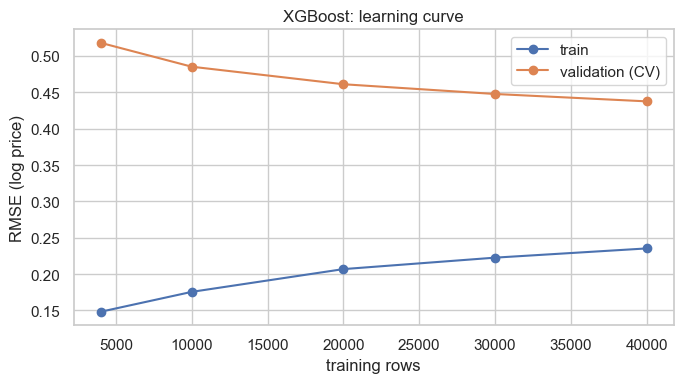

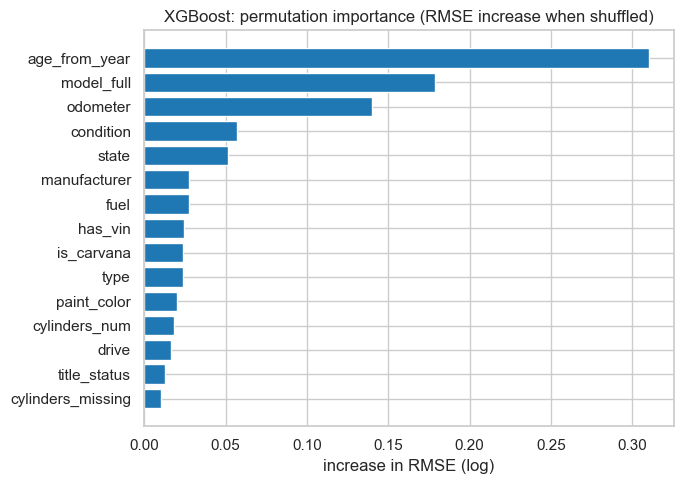

In [30]:
# learning curve on the tuning subsample: does more training data still help?
lc_est = clone(spec[[s[0] for s in spec].index(BEST)][1])
if BEST == "XGBoost":
    lc_est.set_params(learning_rate=0.1, n_estimators=XGB_SEARCH_TREES)      # same fast setting the search used
sizes, lc_tr, lc_va = learning_curve(lc_est, sub_data.get(BEST, Xt_sub), y_sub, cv=cv3, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
                                     scoring="neg_root_mean_squared_error", n_jobs=1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, -lc_tr.mean(1), "o-", label="train"); ax.plot(sizes, -lc_va.mean(1), "o-", label="validation (CV)")
ax.set(title=f"{BEST}: learning curve", xlabel="training rows", ylabel="RMSE (log price)"); ax.legend()
plt.tight_layout(); plt.show()

# permutation importance on a 20k test slice (the model never trained on test, so this shows what it relies on)
n_pi = min(20_000, len(y_te))
pi_idx = np.random.default_rng(SEED).choice(len(y_te), n_pi, replace=False)
pi = permutation_importance(best_model, TEST[key].iloc[pi_idx], y_te.iloc[pi_idx], n_repeats=3, random_state=SEED,
                            scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=TEST[key].columns).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color="tab:blue")
ax.set(title=f"{BEST}: permutation importance (RMSE increase when shuffled)", xlabel="increase in RMSE (log)")
plt.tight_layout(); plt.show()

In [31]:
results_exp = {'learning curve (60k tuning subsample, up to 40k training rows per fold)': [
               'validation error keeps falling as rows are added (about 0.52 at 4k rows to 0.44 at 40k) and has not flattened',
                'train error rises (0.07 to 0.26) and the gap closes from 0.45 to 0.18 but is still large',
                'so more data would still help: this is a variance problem not a problem of the model being too simple',
                'this fits the full-train result: with 184k rows the CV RMSE is about 0.40, lower than anything the 40k curve shows',
                'the main way to improve further is more rows or stronger regularisation not a more complex model'
                ],
 'permutation importance (RMSE increase when one column is shuffled)': [
 'age_from_year is the most important by far (+0.31 RMSE), then model_full (+0.17) and odometer (+0.13)',
    'condition (+0.055), state (+0.048) and manufacturer (+0.03) come next; fuel, Carvana, has_vin and all the other columns are each below +0.03',
    'so three columns carry most of the prediction: how old the car is, what model it is and how many miles it has done, the same story as the Ridge coefficients',
    'manufacturer ranks low because model_full already contains the brand; shuffling one of two overlapping columns hurts less',
    'state matters more than manufacturer: where a car is sold changes its price',
    'has_vin and is_carvana give a small gain (about +0.02 each), and cylinders_missing and title_status are last'
    ],
 'caveat': 'importance was measured on 20k test rows with 3 repeats; it shows what the model uses, not what causes the price'}

blend = 0.00 x Ridge + 1.00 x XGBoost
CV RMSE (out-of-fold): blend 0.4020 vs XGBoost alone 0.4020
test RMSE            : blend 0.3991 (95% CI 0.3909-0.4076) vs XGBoost alone 0.3991
verdict: no gain, drop the blend


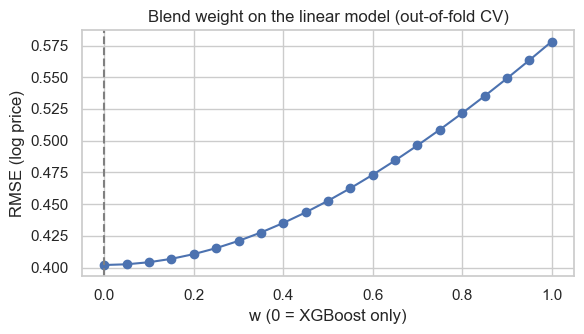

In [32]:
lin_name = min(["Ridge", "Lasso"], key=lambda n: results.loc[n, "cv_rmse"])
ws = np.linspace(0, 1, 21)
blend_cv = [root_mean_squared_error(y_tr, w * oof_preds[lin_name] + (1 - w) * oof_preds["XGBoost"]) for w in ws]
w_best = ws[int(np.argmin(blend_cv))]
blend_test = w_best * test_preds[lin_name] + (1 - w_best) * test_preds["XGBoost"]
ev = evaluate(y_te, blend_test, p_te)
lo, hi = bootstrap_rmse_ci(np.asarray(y_te) - blend_test)
print(f"blend = {w_best:.2f} x {lin_name} + {1 - w_best:.2f} x XGBoost")
print(f"CV RMSE (out-of-fold): blend {min(blend_cv):.4f} vs XGBoost alone {results.loc['XGBoost', 'cv_rmse']:.4f}")
print(f"test RMSE            : blend {ev['rmse_log']:.4f} (95% CI {lo:.4f}-{hi:.4f}) vs XGBoost alone {results.loc['XGBoost', 'test_rmse_log']:.4f}")
print("verdict:", "KEEP the blend" if min(blend_cv) < results.loc["XGBoost", "cv_rmse"] - 1e-4 else "no gain, drop the blend")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ws, blend_cv, "o-"); ax.axvline(w_best, color="grey", ls="--")
ax.set(title="Blend weight on the linear model (out-of-fold CV)", xlabel="w (0 = XGBoost only)", ylabel="RMSE (log price)")
plt.tight_layout(); plt.show()

In [ ]:
results_exp = {'result': [
    'the blend error is lowest at weight 0 (XGBoost only) and rises smoothly as more linear model is added',
    'so the best blend is 100% XGBoost, its CV and test scores equal XGBoost alone, and the verdict is: drop the blend',
    'the final model is therefore XGBoost alone'
    ],
 'why it did not help': [
    'a blend only helps when two models make different mistakes; the linear model is far worse (0.578 vs about 0.40) and what it gets right XGBoost already gets right',
    'the weight was picked on out-of-fold predictions, not on test, so the test set stays clean'
    ],
 'caveat': 'only Ridge (the better of Ridge and Lasso) was tried; Ridge + splines + interactions (0.4957) was not, but it is also much weaker than XGBoost'}

In [34]:
joblib.dump({"name": BEST, "model": best_model, "data_key": key, "columns": list(TEST[key].columns)}, "models/best_model.joblib")
summary = results[["cv_rmse", "cv_std", "test_rmse_log", "ci_low", "ci_high", "test_r2_log", "test_mae_usd", "test_mdape_pct"]]
print("saved: models/best_model.joblib")
display(summary)

saved: models/best_model.joblib


,cv_rmse,cv_std,test_rmse_log,ci_low,ci_high,test_r2_log,test_mae_usd,test_mdape_pct
model,,,,,,,,
XGBoost,0.4020,0.0064,0.3991,0.3902,0.4082,0.8056,"2,960.9790",13.8968
Random Forest,0.4501,0.0052,0.4455,0.4368,0.4539,0.7577,"3,456.9846",16.5411
Ridge + splines + interactions,0.4957,0.0047,0.4977,0.4875,0.5078,0.6976,"3,886.7613",17.9354
Decision Tree,0.5362,0.0047,0.5304,0.5214,0.5394,0.6565,"4,530.1555",22.9856
Ridge,0.5781,0.0050,0.5804,0.5718,0.5900,0.5888,"4,952.4574",24.5520
Lasso,0.5781,0.0050,0.5804,0.5719,0.5896,0.5888,"4,953.0171",24.5719
"Linear (age, odometer)",0.7522,0.0027,0.7547,0.7473,0.7626,0.3046,"7,358.5976",41.0316
Dummy (median),0.9068,0.0015,0.9083,0.9021,0.9147,-0.0070,"9,567.8822",55.9096


In [ ]:
results_exp = {'saved': 'models/best_model.joblib holds the XGBoost model, the column order it expects and the data copy it was trained on',
 'final result': ['XGBoost: CV RMSE 0.4020 +/- 0.0064, test RMSE 0.3991 (95% interval 0.390 to 0.408), test R2 0.81',
                  'test is inside the CV range and inside the interval, so the CV score is a fair estimate of how the model will do on new cars',
                  'in dollars: a typical car is priced within 14% (MdAPE) and the average miss is about $3,000'],
 'reading the table': 'rows are sorted by CV RMSE; the summary table only contains the columns needed for the report'}

In [36]:
final_summary = {'best model': 'XGBoost with native categorical splits (3162 trees, learning rate 0.03): test RMSE 0.3991 in log price, MAE about $2,960 MdAPE about 14%',
 'what worked': ['non-linear models: a straight-line model could not go below 0.58 whatever the alpha, trees reach 0.40',
                 'adding splines and interactions to Ridge (-14%) shows the price pattern is non-linear and brand-specific',
                 'native categorical handling of model_full in XGBoost (-2.6% on the subsample)',
                 'a lower learning rate with early stopping (0.4375 -> 0.3916 on a larger training slice)'],
 'what did not': ['Lasso: nothing to drop, same score as Ridge and about 100x slower',
                  'alpha tuning for Ridge, a wider Random Forest search and the blend: all within noise or no gain'],
 'where the model is weak': ['old cars (over 25 years, MdAPE about 34%) and cheap cars (under $5k, about 25%)',
                             'it squeezes towards the middle: cheap cars are predicted too high, expensive ones too low',
                             'listings with placeholder prices or hidden damage'],
 'issues to consider': ['VIN-less ads were de-duplicated only by identical content, so a re-posted ad could sit in both train and validation: CV may be slightly optimistic',
                        'tuning used a 60k subsample, so the best settings may shift a little on the full data',
                        'dollar predictions are the median, not the mean, so they run slightly low',
                       'importances and error groups describe the model, not the causes of price']}